In [ ]:
from google.colab import files

uploaded = files.upload()

Saving cleaned_heart_disease.csv to cleaned_heart_disease.csv


In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

# Load dataset
df = pd.read_csv("cleaned_heart_disease.csv")

# Remove index column if present
df = df.drop(columns=["Unnamed: 0"], errors="ignore")

# -----------------------------
#Single Variable Linear Regression
X_single = df[["Age"]]
y = df["HealthScore"]

X_train, X_test, y_train, y_test = train_test_split(
    X_single, y, test_size=0.2, random_state=42
)

single_model = LinearRegression()
single_model.fit(X_train, y_train)

y_pred = single_model.predict(X_test)

print("R2:", r2_score(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))

R2: 0.07855934572017542
MSE: 417.29019985735727


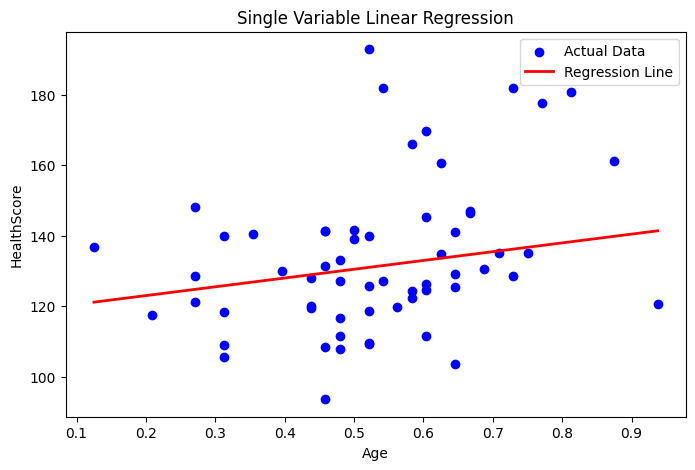

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Convert DataFrame column to NumPy array
x = X_test.iloc[:, 0].values
y = y_test.values

# Sort values for a straight regression line
sorted_index = np.argsort(x)

plt.figure(figsize=(8,5))

# Scatter plot of actual data
plt.scatter(x, y, color='blue', label='Actual Data')

# Regression line
plt.plot(x[sorted_index],
         y_pred[sorted_index],
         color='red',
         linewidth=2,
         label='Regression Line')

plt.xlabel("Age")
plt.ylabel("HealthScore")
plt.title("Single Variable Linear Regression")
plt.legend()

plt.show()

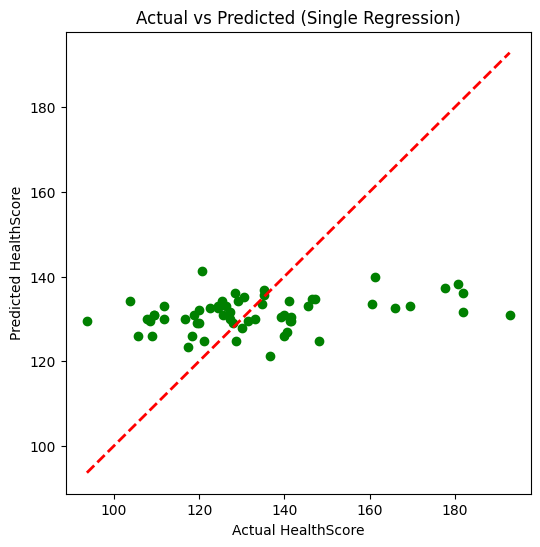

In [ ]:
#Actual vs Predicted Plot
plt.figure(figsize=(6,6))

plt.scatter(y_test, y_pred, color='green')

plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()],
         'r--',
         linewidth=2)

plt.xlabel("Actual HealthScore")
plt.ylabel("Predicted HealthScore")
plt.title("Actual vs Predicted (Single Regression)")

plt.show()

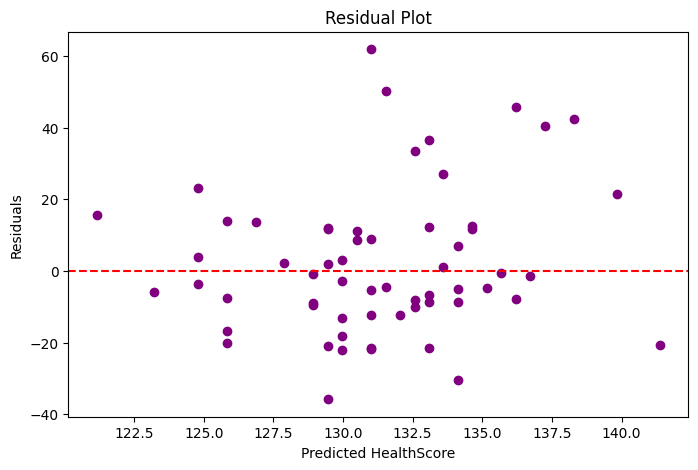

In [ ]:
#Residual Plot
residuals = y_test - y_pred

plt.figure(figsize=(8,5))

plt.scatter(y_pred, residuals, color='purple')

plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel("Predicted HealthScore")
plt.ylabel("Residuals")
plt.title("Residual Plot")

plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

# Independent variables
X_multi = df.drop(columns=["HealthScore"])

# Dependent variable
y_multi = df["HealthScore"]

# Train-Test Split
X_train_multi, X_test_multi, y_train_multi, y_test_multi = train_test_split(
    X_multi, y_multi, test_size=0.2, random_state=42
)

# Train the model
multi_model = LinearRegression()
multi_model.fit(X_train_multi, y_train_multi)

# Predictions
y_pred_multi = multi_model.predict(X_test_multi)

# Evaluation
print("Intercept:", multi_model.intercept_)
print("\nCoefficients:")

coef_df = pd.DataFrame({
    "Feature": X_multi.columns,
    "Coefficient": multi_model.coef_
})

print(coef_df)

print("\nR² Score:", r2_score(y_test_multi, y_pred_multi))
print("Mean Squared Error:", mean_squared_error(y_test_multi, y_pred_multi))

Intercept: -8.526512829121202e-14

Coefficients:
        Feature   Coefficient
0           Age -8.809927e-15
1           Sex  6.272760e-15
2        RestBP  1.000000e+00
3          Chol  1.000000e+00
4           Fbs -1.541291e-15
5       RestECG  4.945767e-17
6         MaxHR  1.343344e-16
7         ExAng  1.445472e-15
8       Oldpeak -5.578751e-16
9         Slope  2.903241e-15
10           Ca  1.720075e-15
11         Thal  2.081866e-15
12          AHD -1.572907e-15
13  ChestPain_0 -6.942928e-16
14  ChestPain_1 -5.716479e-17
15  ChestPain_2  1.171162e-15
16  ChestPain_3 -5.240849e-16
17     HighRisk  2.860559e-15

R² Score: 1.0
Mean Squared Error: 8.885729236409478e-28


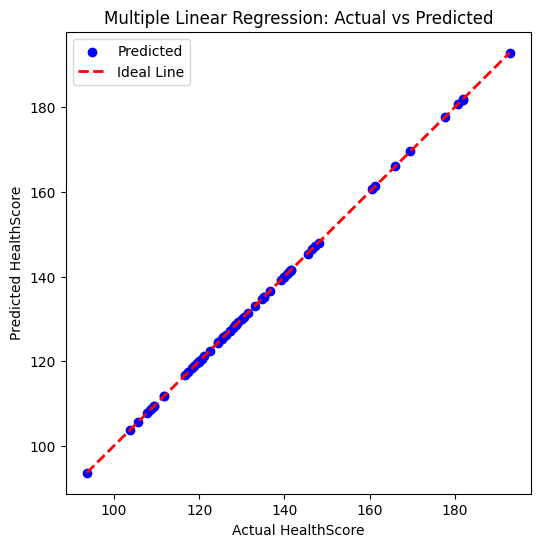

In [ ]:
#Actual vs Predicted Plot
import matplotlib.pyplot as plt

plt.figure(figsize=(6,6))

plt.scatter(y_test_multi, y_pred_multi,
            color='blue',
            label='Predicted')

plt.plot(
    [y_test_multi.min(), y_test_multi.max()],
    [y_test_multi.min(), y_test_multi.max()],
    color='red',
    linestyle='--',
    linewidth=2,
    label='Ideal Line'
)

plt.xlabel("Actual HealthScore")
plt.ylabel("Predicted HealthScore")
plt.title("Multiple Linear Regression: Actual vs Predicted")
plt.legend()

plt.show()

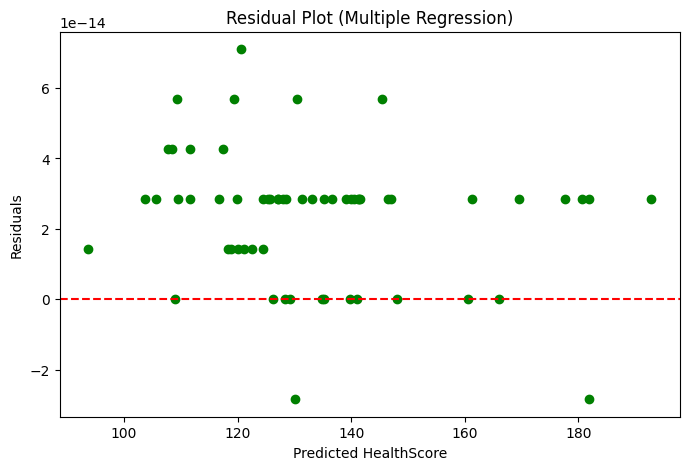

In [ ]:
#Residual Plot
residuals = y_test_multi - y_pred_multi

plt.figure(figsize=(8,5))

plt.scatter(y_pred_multi,
            residuals,
            color='green')

plt.axhline(y=0,
            color='red',
            linestyle='--')

plt.xlabel("Predicted HealthScore")
plt.ylabel("Residuals")
plt.title("Residual Plot (Multiple Regression)")

plt.show()

<Figure size 1200x600 with 0 Axes>

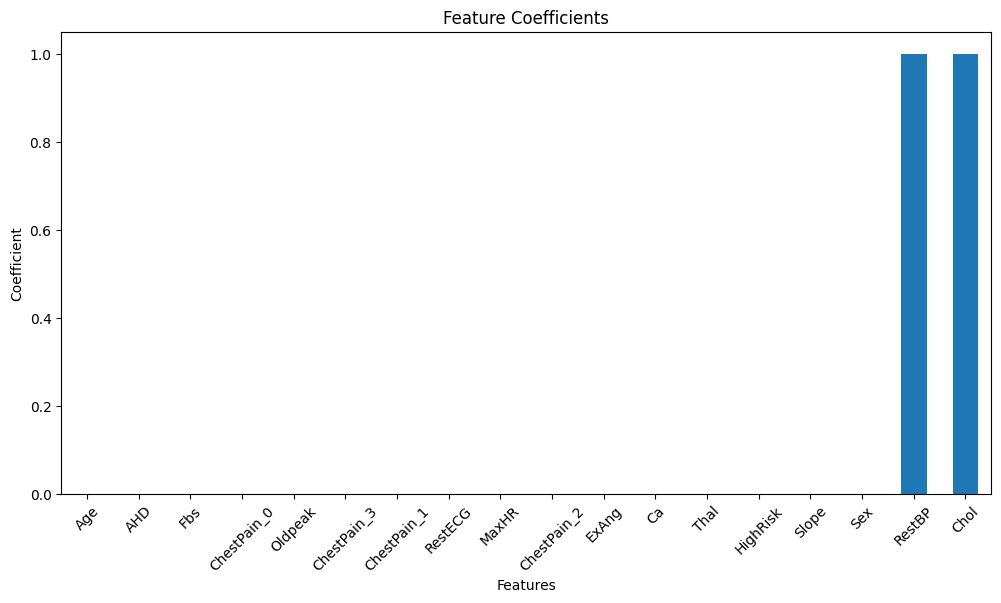

In [ ]:
plt.figure(figsize=(12,6))

coef_df.sort_values("Coefficient").plot(
    x="Feature",
    y="Coefficient",
    kind="bar",
    legend=False,
    figsize=(12,6)
)

plt.title("Feature Coefficients")
plt.xlabel("Features")
plt.ylabel("Coefficient")

plt.xticks(rotation=45)

plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
import pandas as pd

# Remove leakage features
X_multi2 = df.drop(columns=["HealthScore", "RestBP", "Chol"])

# Target
y_multi2 = df["HealthScore"]

# Train-test split
X_train2, X_test2, y_train2, y_test2 = train_test_split(
    X_multi2,
    y_multi2,
    test_size=0.2,
    random_state=42
)

# Train model
model2 = LinearRegression()
model2.fit(X_train2, y_train2)

# Prediction
y_pred2 = model2.predict(X_test2)

# Evaluation
print("Intercept:", model2.intercept_)

coef_df2 = pd.DataFrame({
    "Feature": X_multi2.columns,
    "Coefficient": model2.coef_
})

print("\nCoefficients")
print(coef_df2)

print("\nR² Score:", r2_score(y_test2, y_pred2))
print("MSE:", mean_squared_error(y_test2, y_pred2))

Intercept: 105.43791774878018

Coefficients
        Feature  Coefficient
0           Age     8.285267
1           Sex    -2.641592
2           Fbs     2.779192
3       RestECG     0.772976
4         MaxHR     0.091946
5         ExAng     2.350858
6       Oldpeak     1.135863
7         Slope    -0.107701
8            Ca    -0.053687
9          Thal     0.072305
10          AHD     1.930044
11  ChestPain_0    -1.969764
12  ChestPain_1     0.339020
13  ChestPain_2     0.820388
14  ChestPain_3     0.810357
15     HighRisk    29.331838

R² Score: 0.6445350384050496
MSE: 160.97840287085813


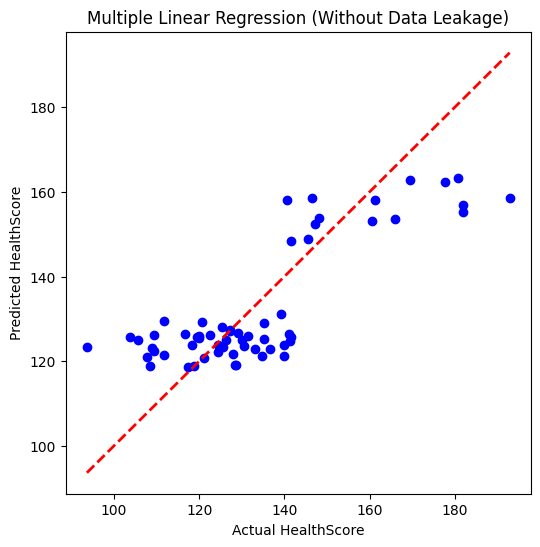

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,6))

plt.scatter(y_test2, y_pred2, color='blue')

plt.plot(
    [y_test2.min(), y_test2.max()],
    [y_test2.min(), y_test2.max()],
    'r--',
    linewidth=2
)

plt.xlabel("Actual HealthScore")
plt.ylabel("Predicted HealthScore")
plt.title("Multiple Linear Regression (Without Data Leakage)")

plt.show()

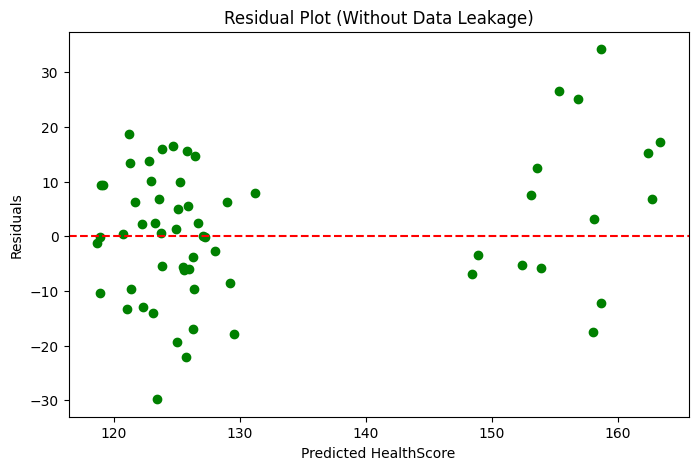

In [ ]:
#Residual Plot
residuals = y_test2 - y_pred2

plt.figure(figsize=(8,5))

plt.scatter(y_pred2, residuals, color='green')

plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel("Predicted HealthScore")
plt.ylabel("Residuals")
plt.title("Residual Plot (Without Data Leakage)")

plt.show()

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving Salary_dataset.csv to Salary_dataset.csv


In [ ]:
import pandas as pd

df = pd.read_csv("Salary_dataset.csv")

# Remove index column
df.drop(columns=["Unnamed: 0"], inplace=True)

df.head()

,YearsExperience,Salary
0,1.2,39344.0
1,1.4,46206.0
2,1.6,37732.0
3,2.1,43526.0
4,2.3,39892.0


In [ ]:
df.info()
df.describe()
df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 2 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   YearsExperience  30 non-null     float64
 1   Salary           30 non-null     float64
dtypes: float64(2)
memory usage: 612.0 bytes


,0
YearsExperience,0
Salary,0


In [ ]:
X = df[["YearsExperience"]]
y = df["Salary"]

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [ ]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

LinearRegression()

In [ ]:
y_pred = model.predict(X_test)

In [ ]:
from sklearn.metrics import r2_score, mean_squared_error

print("Intercept:", model.intercept_)
print("Coefficient:", model.coef_[0])

print("R² Score:", r2_score(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))

Intercept: 24380.201479473704
Coefficient: 9423.815323030976
R² Score: 0.9024461774180497
MSE: 49830096.855908394


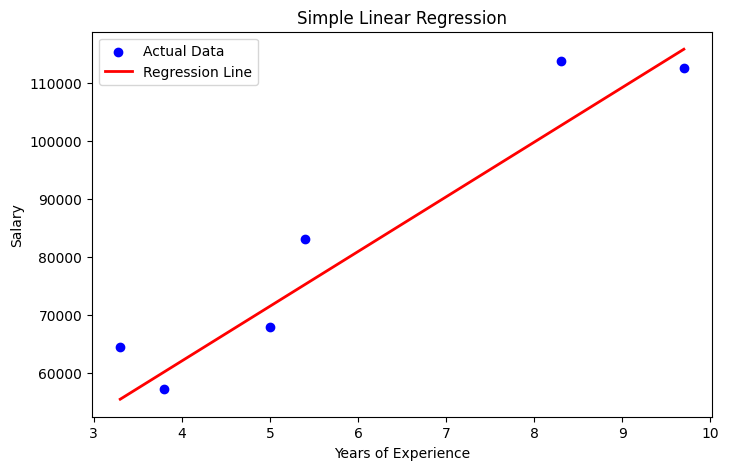

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

x = X_test.iloc[:, 0].values

order = np.argsort(x)

plt.figure(figsize=(8,5))

plt.scatter(x, y_test, color="blue", label="Actual Data")

plt.plot(
    x[order],
    y_pred[order],
    color="red",
    linewidth=2,
    label="Regression Line"
)

plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.title("Simple Linear Regression")
plt.legend()

plt.show()

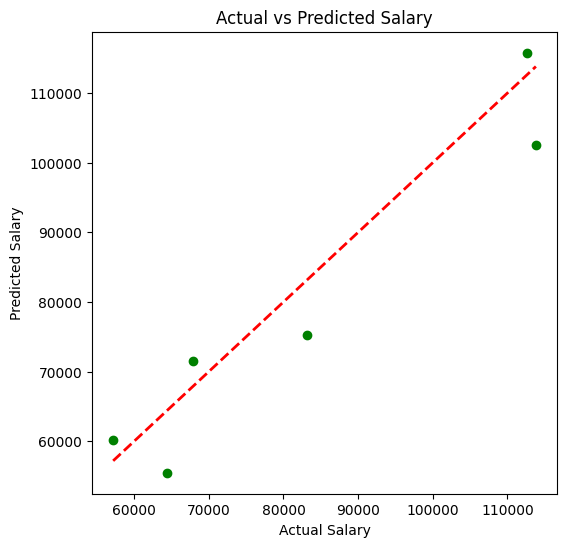

In [ ]:
plt.figure(figsize=(6,6))

plt.scatter(y_test, y_pred, color="green")

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--",
    linewidth=2
)

plt.xlabel("Actual Salary")
plt.ylabel("Predicted Salary")
plt.title("Actual vs Predicted Salary")

plt.show()

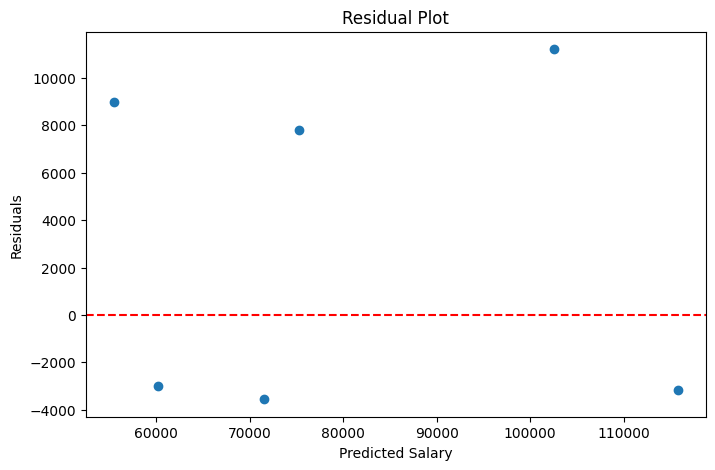

In [ ]:
residuals = y_test - y_pred

plt.figure(figsize=(8,5))

plt.scatter(y_pred, residuals)

plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Predicted Salary")
plt.ylabel("Residuals")
plt.title("Residual Plot")

plt.show()

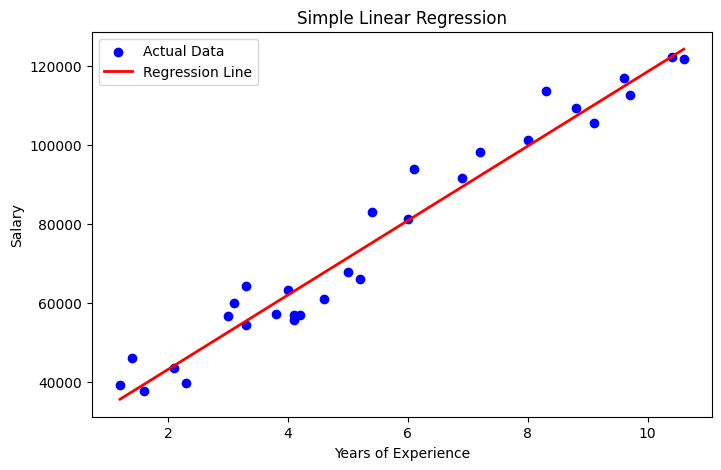

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Sort the data for a clean line
X_sorted = df[["YearsExperience"]].sort_values(by="YearsExperience")
y_line = model.predict(X_sorted)

plt.figure(figsize=(8,5))

plt.scatter(df["YearsExperience"], df["Salary"],
            color="blue", label="Actual Data")

plt.plot(X_sorted, y_line,
         color="red", linewidth=2,
         label="Regression Line")

plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.title("Simple Linear Regression")
plt.legend()

plt.show()

In [ ]:
# Create new features
df["ExperienceSquared"] = df["YearsExperience"] ** 2
df["ExperienceCubed"] = df["YearsExperience"] ** 3

df.head()

,YearsExperience,Salary,ExperienceSquared,ExperienceCubed
0,1.2,39344.0,1.44,1.728
1,1.4,46206.0,1.96,2.744
2,1.6,37732.0,2.56,4.096
3,2.1,43526.0,4.41,9.261
4,2.3,39892.0,5.29,12.167


In [ ]:
X_multi = df[["YearsExperience",
              "ExperienceSquared",
              "ExperienceCubed"]]

y_multi = df["Salary"]

In [ ]:
from sklearn.model_selection import train_test_split

X_train_multi, X_test_multi, y_train_multi, y_test_multi = train_test_split(
    X_multi,
    y_multi,
    test_size=0.2,
    random_state=42
)

In [ ]:
from sklearn.linear_model import LinearRegression

multi_model = LinearRegression()

multi_model.fit(X_train_multi, y_train_multi)

LinearRegression()

In [ ]:
y_pred_multi = multi_model.predict(X_test_multi)

In [ ]:
from sklearn.metrics import r2_score, mean_squared_error
import pandas as pd

print("Intercept:", multi_model.intercept_)

coef_df = pd.DataFrame({
    "Feature": X_multi.columns,
    "Coefficient": multi_model.coef_
})

print("\nCoefficients")
print(coef_df)

print("\nR² Score:", r2_score(y_test_multi, y_pred_multi))
print("MSE:", mean_squared_error(y_test_multi, y_pred_multi))

Intercept: 39318.45851582244

Coefficients
             Feature  Coefficient
0    YearsExperience -1545.685335
1  ExperienceSquared  2130.084724
2    ExperienceCubed  -118.359093

R² Score: 0.9048429887854872
MSE: 48605815.33188688


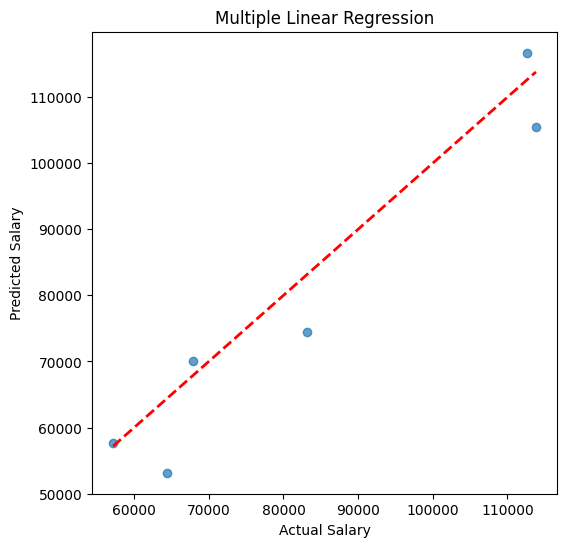

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,6))

plt.scatter(y_test_multi, y_pred_multi,
            alpha=0.7)

plt.plot(
    [y_test_multi.min(), y_test_multi.max()],
    [y_test_multi.min(), y_test_multi.max()],
    "r--",
    linewidth=2
)

plt.xlabel("Actual Salary")
plt.ylabel("Predicted Salary")
plt.title("Multiple Linear Regression")

plt.show()

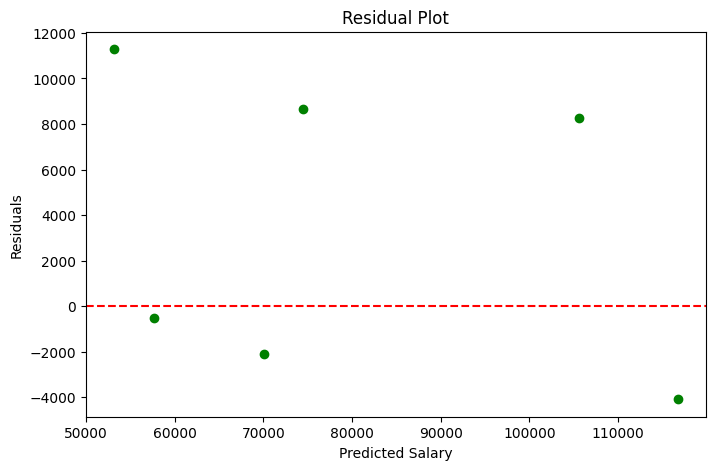

In [ ]:
residuals = y_test_multi - y_pred_multi

plt.figure(figsize=(8,5))

plt.scatter(y_pred_multi,
            residuals,
            color="green")

plt.axhline(y=0,
            color="red",
            linestyle="--")

plt.xlabel("Predicted Salary")
plt.ylabel("Residuals")
plt.title("Residual Plot")

plt.show()

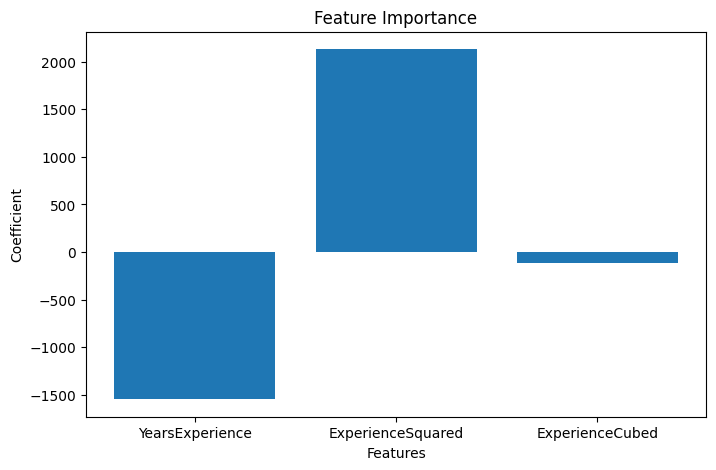

In [ ]:
plt.figure(figsize=(8,5))

plt.bar(coef_df["Feature"],
        coef_df["Coefficient"])

plt.xlabel("Features")
plt.ylabel("Coefficient")
plt.title("Feature Importance")

plt.show()

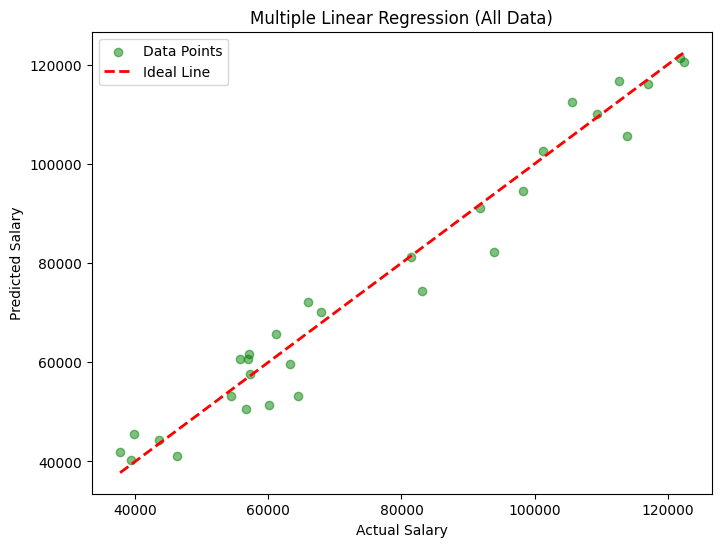

In [ ]:
# Predict on the entire dataset
y_pred_all = multi_model.predict(X_multi)

plt.figure(figsize=(8,6))

plt.scatter(y_multi, y_pred_all,
            color='green',alpha=0.5,
            label='Data Points')

plt.plot(
    [y_multi.min(), y_multi.max()],
    [y_multi.min(), y_multi.max()],
    'r--',
    linewidth=2,
    label='Ideal Line'
)

plt.xlabel("Actual Salary")
plt.ylabel("Predicted Salary")
plt.title("Multiple Linear Regression (All Data)")
plt.legend()

plt.show()